In [116]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import matplotlib
matplotlib.rcParams['figure.figsize'] = (12, 8)

#import warnings
#warnings.filterwarnings('ignore')

# k Nearest Neighbors (kNN)
Метод k ближайших соседей рассчитывает расстояния от нового объекта до всех объектов выборки и, отбирая k ближайших, предсказывает целевую переменную с помощью голосования (в случае классификации) или усреднения (в случае регрессии). \
При этом этот метод можно по-разному настраивать, например можно изменить способ подсчета расстояний или способ взвешивания соседей по расстоянию. \
Для начала скачаем датасет и визуализируем данные.

In [117]:
circ = pd.read_csv('concertriccir2.csv')
circ.head()

,X,Y,class
0,0.70,-0.247,0.0
1,-3.95,2.740,1.0
2,0.15,-2.160,1.0
3,-1.67,-0.942,1.0
4,2.56,-1.850,1.0


<Axes: xlabel='X', ylabel='Y'>

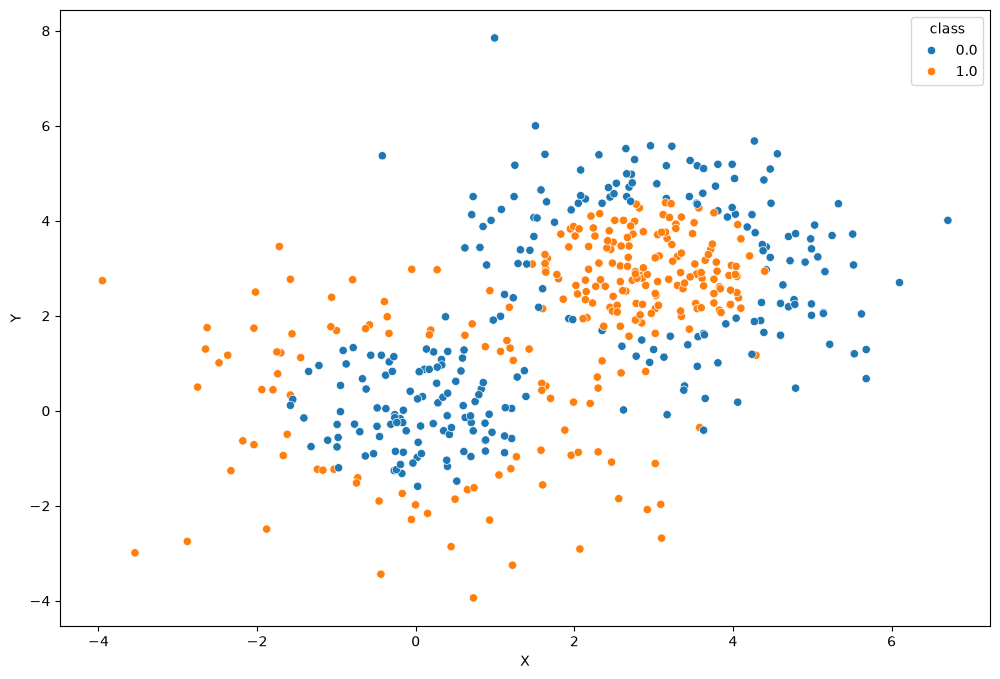

In [118]:
sns.scatterplot(data=circ, x='X', y='Y', hue='class')

**Задание 1.** Обучите логистическую регрессию на данных и нарисуйте разделяющую гиперплоскость (прямую) на рисунке с данными. Как линейный классификатор справился с задачей? Сделайте вывод исходя из геометрии данных и линии разделения. Какой accuracy выйдет на всей выборке (без валидации)?

Коэффициенты:  [[-0.003161  -0.0120486]]
Accuracy:  0.424


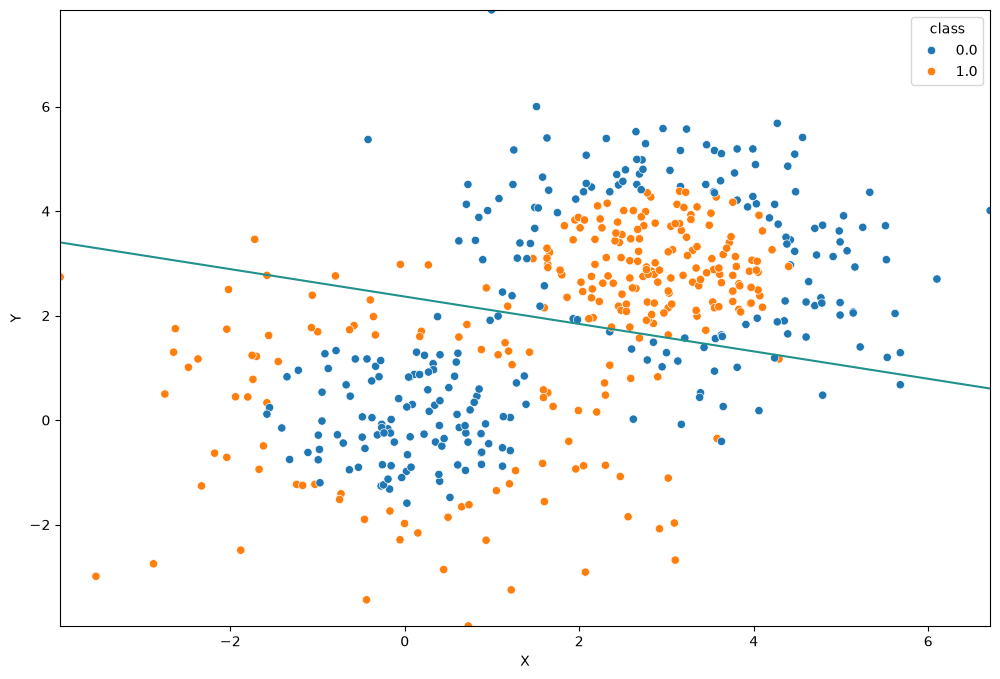

In [119]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression()

X = circ.drop('class', axis=1)
y = circ['class']

logreg.fit(X, y)

print('Коэффициенты: ', logreg.coef_)
print('Accuracy: ', logreg.score(X, y))

sns.scatterplot(data=circ, x='X', y='Y', hue='class')

X_line = np.linspace(min(X['X']), max(X['X']), 100)
y_line = np.linspace(min(X['Y']), max(X['Y']), 100)

X_grid, y_grid = np.meshgrid(X_line, y_line)
points = np.c_[np.ravel(X_grid), np.ravel(y_grid)]

z = logreg.decision_function(points)
z = z.reshape(X_grid.shape)
plt.contour(X_grid, y_grid, z, levels=0)

**Задание 2.** Разделите обучающую выборку и обучите 6 моделей kNN с различным числом соседей из `all_k`, сохраните обученные классификаторы в список. \
Выведите accuracy на тренировочной и тестовой выборке для каждой модели. Каково оптимальное число соседей с точки зрения accuracy?

In [120]:
X = circ[['X', 'Y']].values
y = circ['class'].values.astype('int')

In [121]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, 
                                                    shuffle=True, random_state=2022)

In [122]:
from sklearn.neighbors import KNeighborsClassifier
all_k = [1, 3, 10, 30, 40, 60]

all_clfs = []
for k in all_k:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    print(f'Accuracy на train для k={k}', knn.score(X_train, y_train))
    print(f'Accuracy на test для k={k}: ', knn.score(X_test, y_test))
    all_clfs.append(knn)

# Лучший по accuracy это k = 1

Accuracy на train для k=1 1.0
Accuracy на test для k=1:  0.89
Accuracy на train для k=3 0.9475
Accuracy на test для k=3:  0.87
Accuracy на train для k=10 0.915
Accuracy на test для k=10:  0.85
Accuracy на train для k=30 0.8525
Accuracy на test для k=30:  0.74
Accuracy на train для k=40 0.8
Accuracy на test для k=40:  0.75
Accuracy на train для k=60 0.6925
Accuracy на test для k=60:  0.73


**Задание 3.** (бонусное) Скачайте библиотку [mlxtend](http://rasbt.github.io/mlxtend/#examples) для визуализации решающих поверхностей. 
В документации можно ознакомиться с [примерами](http://rasbt.github.io/mlxtend/user_guide/plotting/plot_decision_regions/) изображения решающих поверхностей для различных моделей. \
Построим несколько таких графиков для шести обученных нами kNN.

1. Подберите параметры `gridspec.GridSpec()` и `itertools.product()` для нашего числа классификаторов. 
2. Удобно перед визулизацией сохранить обученные классификаторы в список `all_clfs`.
3. Проявите терпение! Отрисовка решающих поверхностей может занимать пару минут.

In [123]:
import mlxtend
from mlxtend.plotting import plot_decision_regions
import matplotlib.gridspec as gridspec
import itertools

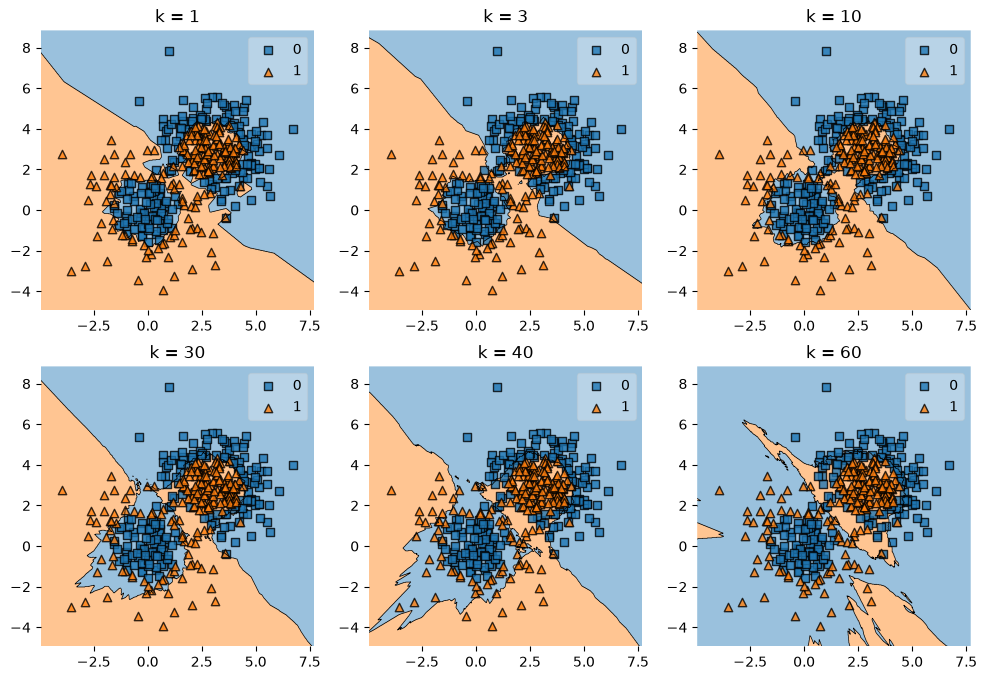

In [124]:
gs = gridspec.GridSpec(2, 3)

labels = ['k = 1', 'k = 3', 'k = 10', 'k = 30', 'k = 40', 'k = 60']

for (r, c), label in zip(itertools.product([0, 1], [0, 1, 2]), labels):
    ax = plt.subplot(gs[r, c])
    plot_decision_regions(X_train, y_train, clf=all_clfs[r * 3 + c], ax=ax)
    ax.set_title(label)

# 1) Поверхность с ростом числа соседей меняется так: области становятся все менее связанными друг с другом
# особенно те, что были не сильно связаны, и устойчивы те области, где плотность соседей одного класса высокая

# 2) Скорее k=3. k=1 по графику очень похожа на k=3, но есть смысл между ними выбрать k=3, так как k=3
# не сильно проигрывает по accuracy и геометрия практически та же, но устойчивость к шуму выше.
# Accuracy у k=1 на train и на test сильно различаются: это говорит о более плохой обобщаемости модели
# У k=3 с разницей между train и test чуть получше, и почти не хуже чем у k=10, но при этом accuracy заметно
# лучше чем у k=10
# k = 30 и дальше уже строит не такую хорошую геометрию и границы не такие хорошие, как у тройки до этого
# Да и accuracy там уже заметно хуже.
# k = 3 - кажется оптимальным балансом между accuracy, геометрией, и обобщаемостью модели

# 3) Да, конечно. Это видно как на графиках, так и по accuracy. На графике logreg'а видно, что разделение прямой
# сильно хуже по accuracy, чем knn. На данном датасете knn заметно лучше по качеству модели.


1. Как меняется решающая поверхность с ростом числа соседей?
2. Какое оптимальное число соседей с точки зрения устройства данных и геометрии решающих поверхностей? Поясните свой ответ, опираясь на полученные графики.
3. Лучше ли справляется kNN по сравнению с логистической регрессией?

**Задание 4.** Скачайте уже известный вам датасет [SigmaCabs](https://www.kaggle.com/datasets/arashnic/taxi-pricing-with-mobility-analytics). Обучите классификатор kNN на отнормированных и не отнормированных данных, подобрав лучшие гиперпараметры среди $k \in [1, 5, 10]$. Замерьте качество на тестовой выборке. \
Почему нормирование данных помогает улучшить качество?

In [125]:
df = pd.read_csv('processed_sigma_cabs.csv')
df.head()

,Trip_Distance,Customer_Since_Months,Life_Style_Index,Customer_Rating,Cancellation_Last_1Month,Var1,Var2,Var3,Surge_Pricing_Type,Type_of_Cab_B,...,Destination_Type_F,Destination_Type_G,Destination_Type_H,Destination_Type_I,Destination_Type_J,Destination_Type_K,Destination_Type_L,Destination_Type_M,Destination_Type_N,Gender_Male
0,6.77,1.0,2.42769,3.90500,0,40.0,46,60,2,1,...,0,0,0,0,0,0,0,0,0,0
1,29.47,10.0,2.78245,3.45000,0,38.0,56,78,2,1,...,0,0,0,0,0,0,0,0,0,1
2,41.58,10.0,2.79805,3.50125,2,61.0,56,77,2,1,...,0,0,0,0,0,0,0,0,0,1
3,61.56,10.0,2.79805,3.45375,0,61.0,52,74,3,0,...,0,0,0,0,0,0,0,0,0,1
4,54.95,10.0,3.03453,3.40250,4,51.0,49,102,2,0,...,0,0,0,0,0,0,0,0,0,1


In [126]:
X = df.drop('Surge_Pricing_Type', axis=1)
y = df['Surge_Pricing_Type']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, 
                                                    shuffle=True, random_state=2022)

In [127]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pipe_scaled = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsClassifier())
])

grid_params = {
    'model__n_neighbors': [1, 5, 10]
}

grid = GridSearchCV(pipe_scaled, grid_params, cv=5)
grid.fit(X_train, y_train)
print('Наилучшие параметры: ', grid.best_params_)
print('Accuracy для модели с масштабированием: ', grid.score(X_test, y_test))

pipe_unscaled = Pipeline([
    ('model', KNeighborsClassifier())
])

grid = GridSearchCV(pipe_unscaled, grid_params, cv=5)
grid.fit(X_train, y_train)
print('Наилучшие параметры: ', grid.best_params_)
print('Accuracy для модели без масштабирования: ', grid.score(X_test, y_test))

# После масштабирования accuracy вырос с 0.47 до 0.66. Масштабирование важно для KNN, так как KNN
# работает с расстояниями, и при отсутствии масштабирования один признак с бОльшим масштабом может доминировать
# хоть на самом деле этот признак может уступать по значимости другому признаку с меньшим масштабом
# Или может быть ситуация, когда другой тоже важный признак имеет меньшее значение из-за меньшего масштаба
# и вклад признака недооценивается

Наилучшие параметры:  {'model__n_neighbors': 10}
Accuracy для модели с масштабированием:  0.6607678578209851
Наилучшие параметры:  {'model__n_neighbors': 10}
Accuracy для модели без масштабирования:  0.4703603843086621


**Задание 5.** Обучите классификатор kNN на отнормированных данных с помощью метрики Минковского. 
$$
\rho(x, z) = \bigg(\sum_i |x_i - z_i|^p\bigg) ^{1/p}
$$

Значение параметра `p` возьмите равным единице. Замерьте качество на тестовой выборке и сравните с предыдущим заданием, где `p = 2`.

In [128]:
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsClassifier(n_neighbors=10, p=1, metric='minkowski'))
])

pipe.fit(X_train, y_train)
print('Accuracy для модели с p=1: ', pipe.score(X_test, y_test))

# При p=1 accuracy чуть чуть больше. Но разница маленькая

Accuracy для модели с p=1:  0.6611476094634109


**Задание 6.** Скачайте датасет [California Housing Prices](https://www.kaggle.com/datasets/camnugent/california-housing-prices), в котором мы будем предсказывать среднюю стоимость жилья. В качестве признаков будем использовать `['longitude', 'latitude']`, посмотрите на них с помощью scatterplot. \
По какой характеристике наш kNN регрессор в этом случае подбирает соседей?

1. Обучите обыкновенную линейную регрессию и замерьте RMSE на тренировочной и тестовой выборках.
2. Обучите kNN регрессор на отнормированных данных, подобрав лучшие гиперпараметры $k \in [1, 2, ..., 9]$. 
3. Обучите kNN регрессор с гауссовским ядром, взяв параметр k из предыдущего пункта и подобрав оптимальное значение ширины окна среди предложенных $h \in np.arange(0.02, 0.1, 0.01)$.

Как ширина окна влияет на веса при усреднении ответа по соседям? 

In [129]:
df = pd.read_csv('housing.csv')
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


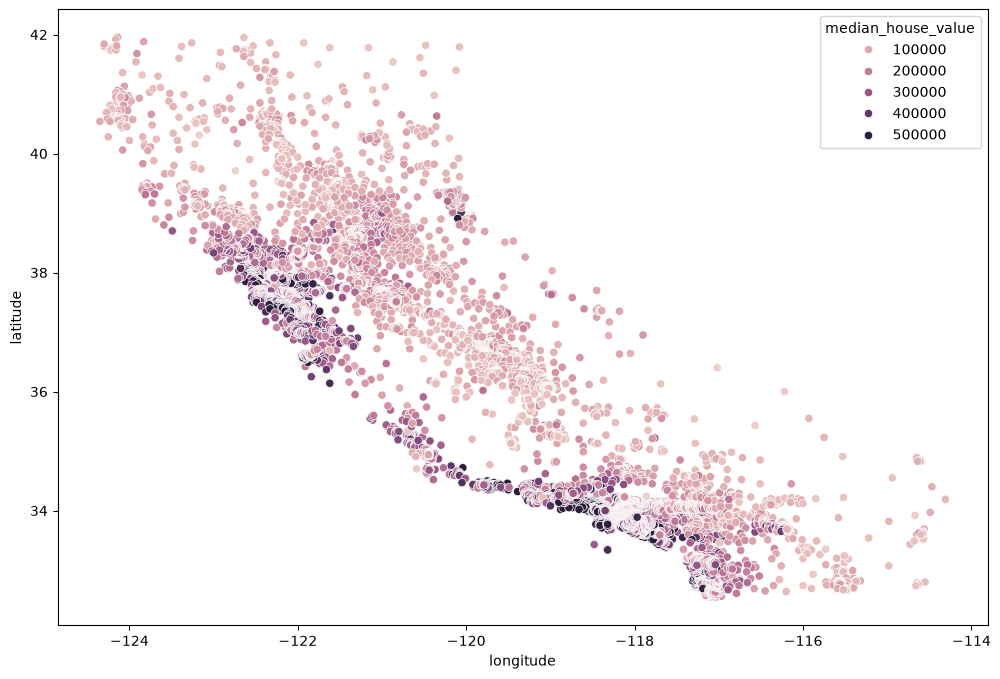

In [130]:
X = df[['longitude', 'latitude']]
y = df['median_house_value']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, 
                                                    shuffle=True, random_state=2022)
sns.scatterplot(data=X, x='longitude', y='latitude', hue=y);

In [133]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import cross_val_score

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

linreg = LinearRegression().fit(X_train, y_train)
y_pred_train = linreg.predict(X_train)
y_pred_test = linreg.predict(X_test)


print('RMSE линейной регрессии на train',root_mean_squared_error(y_train, y_pred_train))
print('RMSE линейной регрессии на test', root_mean_squared_error(y_test, y_pred_test))

param_grid = {
    'model__n_neighbors': np.arange(1, 10)
}

pipe_knn1 = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsRegressor(n_neighbors=6))
])

grid = GridSearchCV(pipe_knn1, param_grid, cv=5, scoring='neg_root_mean_squared_error')
grid.fit(X_train, y_train)

y_pred_train = grid.predict(X_train)
y_pred_test = grid.predict(X_test)

# Здесь мы получили 
# Наилучшие параметры для knn1:  {'model__n_neighbors': np.int64(6)}
# Поэтому в pipe_knn1 для model пошло n_neighbors=6
# print('Наилучшие параметры для knn1: ', grid.best_params_)

print()
print('RMSE knn1 на train', root_mean_squared_error(y_train, y_pred_train))
print('RMSE knn1 на test', root_mean_squared_error(y_test, y_pred_test))

rmse = []

for h in np.arange(0.02, 0.1, 0.01):
    def kernel(distances):
        const = 1 / (np.sqrt(2 * np.pi))
        power = (-1/2) * ((distances)**2) / h**2
    
        return const * np.exp(power)

    pipe_knn2 = Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsRegressor(weights=kernel, n_neighbors=6))
    ])

    # Здесь видно, что при увеличении h rmse нашей модели увеличивается
    #print(rmse)
    rmse.append(-(cross_val_score(pipe_knn2, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error').mean()))

h = np.arange(0.02, 0.1, 0.01)
best_h = h[np.argmin(rmse)]
h = best_h

def kernel(distances):
    const = 1 / (np.sqrt(2 * np.pi))
    power = (-1/2) * ((distances)**2) / h**2
    
    return const * np.exp(power)


pipe_knn2 = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsRegressor(weights=kernel, n_neighbors=6))
])

pipe_knn2.fit(X_train, y_train)
y_pred_train = pipe_knn2.predict(X_train)
y_pred_test = pipe_knn2.predict(X_test)

print()
print('RMSE knn2 на train', root_mean_squared_error(y_train, y_pred_train))
print('RMSE knn2 на test', root_mean_squared_error(y_test, y_pred_test))

# Чем меньше h тем быстрее затухание весов, чем больше h тем медленнее затухание весов

RMSE линейной регрессии на train 100948.39976676002
RMSE линейной регрессии на test 98369.87709657701

RMSE knn1 на train 44111.00928333167
RMSE knn1 на test 52704.80168932809

RMSE knn2 на train 42026.18605894102
RMSE knn2 на test 52539.57791414396
